# Pascal VOC 2012: Data Exploration

Inspect object-detection annotations, summarize all 20 categories, and save reproducible training and development-validation splits. This notebook does not train a model.

**Run from top to bottom** using the project’s `Pascal VOC (.venv)` kernel. The notebook assumes its working directory is the repository root and that `VOCdevkit` is a sibling of the repository.

## Evaluation plan

| Role | Images | Source |
|---|---:|---|
| Training | 4,573 | 80% of official detection `train` |
| Development validation | 1,144 | 20% of official detection `train` |
| Final held-out evaluation | 5,823 | Official detection `val`, left untouched here |

The separately downloaded official test images are not used in this approach.


## 1. Read the official training split

Load image IDs from `ImageSets/Main/train.txt`. An ID connects a photo to its XML annotation; reading this list does not load the photos.


In [25]:
from pathlib import Path

dataset_dir = Path("../VOCdevkit/VOC2012").resolve()

train_split = dataset_dir / "ImageSets/Main/train.txt"
train_ids = train_split.read_text().splitlines()

print("Training images:", len(train_ids))
print("First five IDs:", train_ids[:5])


Training images: 5717
First five IDs: ['2008_000008', '2008_000015', '2008_000019', '2008_000023', '2008_000028']


## 2. Connect one image to its annotation

Use an ID to open a JPG photograph and its matching XML file. Extract every object’s category, bounding box, and difficult flag. These are ground-truth labels, not predictions. Only official training images are inspected.


In [26]:
import xml.etree.ElementTree as ET

from PIL import Image

image_id = train_ids[1500]
image_path = dataset_dir / "JPEGImages" / f"{image_id}.jpg"
annotation_path = dataset_dir / "Annotations" / f"{image_id}.xml"

image = Image.open(image_path).convert("RGB")
annotation = ET.parse(annotation_path).getroot()

objects = []
for obj in annotation.findall("object"):
    box = obj.find("bndbox")
    objects.append(
        {
            "name": obj.findtext("name"),
            "xmin": int(box.findtext("xmin")),
            "ymin": int(box.findtext("ymin")),
            "xmax": int(box.findtext("xmax")),
            "ymax": int(box.findtext("ymax")),
            "difficult": int(obj.findtext("difficult", "0")),
        }
    )

print("Image ID:", image_id)
print("Image size (width, height):", image.size)
print("Number of labeled objects:", len(objects))
for obj in objects:
    print(obj)


Image ID: 2008_006329
Image size (width, height): (375, 500)
Number of labeled objects: 2
{'name': 'cat', 'xmin': 57, 'ymin': 47, 'xmax': 182, 'ymax': 336, 'difficult': 0}
{'name': 'cat', 'xmin': 112, 'ymin': 99, 'xmax': 318, 'ymax': 498, 'difficult': 0}


## 3. Visualize the ground-truth boxes

VOC coordinates start at 1 and include both endpoints. For display, subtract 1 from the left/top coordinates and include the final pixel in the width and height. Dashed boxes indicate objects marked `difficult`.


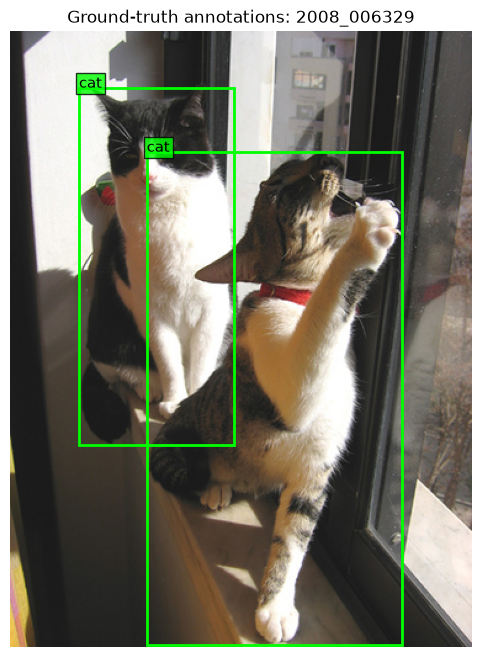

In [27]:
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(image, extent=(0, image.width, image.height, 0))

for obj in objects:
    x = obj["xmin"] - 1
    y = obj["ymin"] - 1
    width = obj["xmax"] - obj["xmin"] + 1
    height = obj["ymax"] - obj["ymin"] + 1

    rectangle = Rectangle(
        (x, y),
        width,
        height,
        fill=False,
        edgecolor="lime",
        linewidth=2,
        linestyle="--" if obj["difficult"] else "-",
    )
    ax.add_patch(rectangle)
    label = obj["name"] + (" (difficult)" if obj["difficult"] else "")
    ax.text(
        x,
        y,
        label,
        color="black",
        fontsize=11,
        bbox={"facecolor": "lime", "alpha": 0.8, "pad": 2},
    )

ax.set_title(f"Ground-truth annotations: {image_id}")
ax.axis("off")
plt.show()


### Visual inspection

Check that each label matches its object and that the box surrounds the annotated visible extent. Notice small, overlapping, occluded, or truncated objects.

To view another example, change the index in `image_id = train_ids[1500]` in section 2, then rerun sections 2 and 3.


## 4. Explore category distributions

Build one table row per annotated object in the official training split. `images` counts distinct photos; `objects` includes difficult instances; `difficult_objects` counts that subset.


In [28]:
import pandas as pd

rows = []

for image_id in train_ids:
    annotation_path = dataset_dir / "Annotations" / f"{image_id}.xml"
    annotation = ET.parse(annotation_path).getroot()

    for obj in annotation.findall("object"):
        rows.append(
            {
                "image_id": image_id,
                "category": obj.findtext("name"),
                "difficult": int(obj.findtext("difficult", "0")),
            }
        )

objects_df = pd.DataFrame(rows)

summary = (
    objects_df.groupby("category")
    .agg(
        images=("image_id", "nunique"),
        objects=("image_id", "size"),
        difficult_objects=("difficult", "sum"),
    )
    .sort_values("objects", ascending=False)
)

summary


,images,objects,difficult_objects
category,,,
person,2142,5019,825
chair,656,1457,279
car,621,1191,178
dog,636,768,12
bottle,399,749,120
cat,540,609,4
bird,399,592,32
pottedplant,289,557,73
sheep,171,509,109


### Plot non-difficult and difficult instances


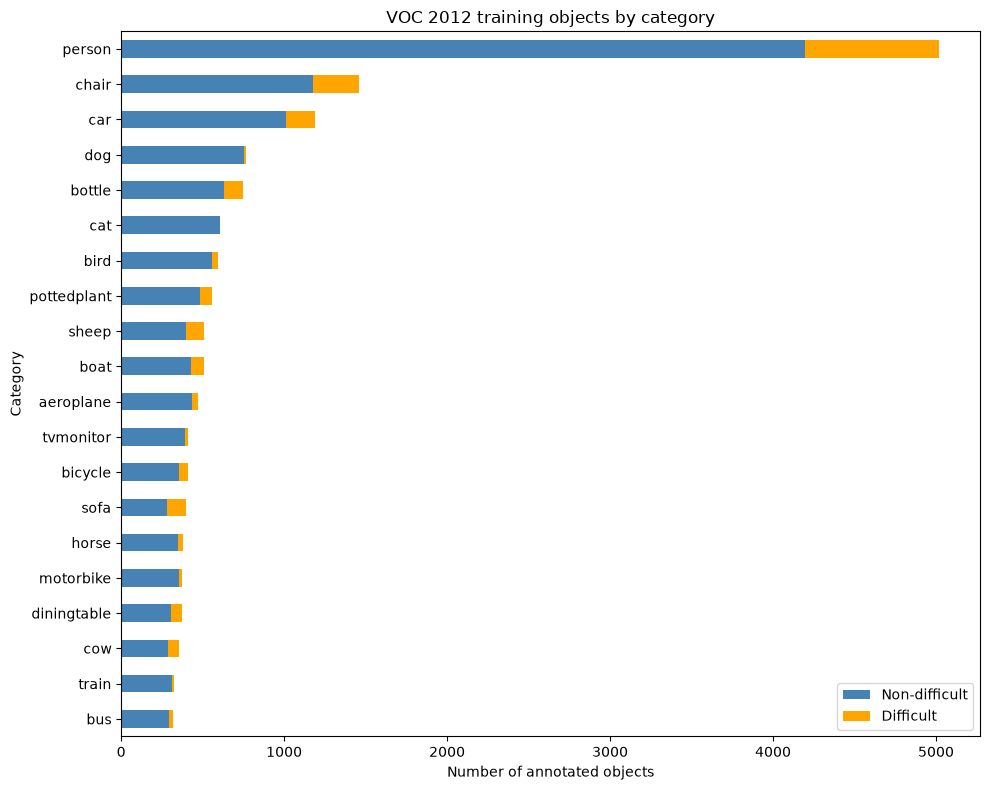

In [29]:
plot_data = pd.DataFrame(
    {
        "Non-difficult": summary["objects"] - summary["difficult_objects"],
        "Difficult": summary["difficult_objects"],
    }
)

ax = plot_data.plot.barh(
    stacked=True,
    figsize=(10, 8),
    color=["steelblue", "orange"],
)

ax.invert_yaxis()
ax.set_xlabel("Number of annotated objects")
ax.set_ylabel("Category")
ax.set_title("VOC 2012 training objects by category")

plt.tight_layout()
plt.show()


The training set is imbalanced: person annotations substantially outnumber other categories. Difficult-object proportions also vary by category. We will report per-class detection performance and preserve the difficult flags for evaluation.

## 5. Create a reproducible development split

Split whole images, keeping all objects in a photo together. `fit_ids` are used for model training; `dev_ids` are used to choose settings. The fixed seed makes this split repeatable. Assertions check disjointness and full coverage of the original training IDs.


In [30]:
from sklearn.model_selection import train_test_split

fit_ids, dev_ids = train_test_split(
    train_ids,
    test_size=0.20,
    random_state=42,
    shuffle=True,
)

print("Training:", len(fit_ids))
print("Development validation:", len(dev_ids))

assert set(fit_ids).isdisjoint(dev_ids)

assert set(fit_ids) | set(dev_ids) == set(train_ids)


Training: 4573
Development validation: 1144


## 6. Save the split manifests

Write the IDs to `splits/train.txt` and `splits/dev.txt` so every experiment uses the same examples. These small text files belong in version control. Rerunning this cell overwrites them with the same split when the inputs and seed are unchanged.


In [31]:
split_dir = Path("splits")
split_dir.mkdir(exist_ok=True)

(split_dir / "train.txt").write_text("\n".join(sorted(fit_ids)) + "\n")

(split_dir / "dev.txt").write_text("\n".join(sorted(dev_ids)) + "\n")


13728

## 7. Check category coverage

Count non-difficult objects in each new split. Every category should have examples in both groups. This check does not remove difficult objects from the underlying annotations.


In [32]:
regular_objects = objects_df[objects_df["difficult"] == 0]

fit_counts = (
    regular_objects[regular_objects["image_id"].isin(fit_ids)]
    .groupby("category")
    .size()
)

dev_counts = (
    regular_objects[regular_objects["image_id"].isin(dev_ids)]
    .groupby("category")
    .size()
)

coverage = (
    pd.DataFrame(
        {
            "training_objects": fit_counts,
            "validation_objects": dev_counts,
        }
    )
    .reindex(summary.index)
    .fillna(0)
    .astype(int)
)

assert (coverage > 0).all().all(), "A category is missing from a split."

coverage


,training_objects,validation_objects
category,,
person,3299,895
chair,950,228
car,819,194
dog,609,147
bottle,496,133
cat,487,118
bird,453,107
pottedplant,363,121
sheep,328,72


In [33]:
from dataset import VOCDetectionDataset

training_dataset = VOCDetectionDataset(
    dataset_dir=dataset_dir,
    split_file="splits/train.txt",
)

print("Training examples:", len(training_dataset))


Training examples: 4573


In [34]:
image, target = training_dataset[0]

print("Image shape:", image.shape)
print("Pixel range:", image.min().item(), image.max().item())
print("Boxes:", target["boxes"])
print("Labels:", target["labels"])
print("Difficult:", target["difficult"])


Image shape: torch.Size([3, 442, 500])
Pixel range: 0.0 1.0
Boxes: tensor([[ 52.,  86., 471., 420.],
        [157.,  43., 289., 167.]])
Labels: tensor([13, 15])
Difficult: tensor([False, False])


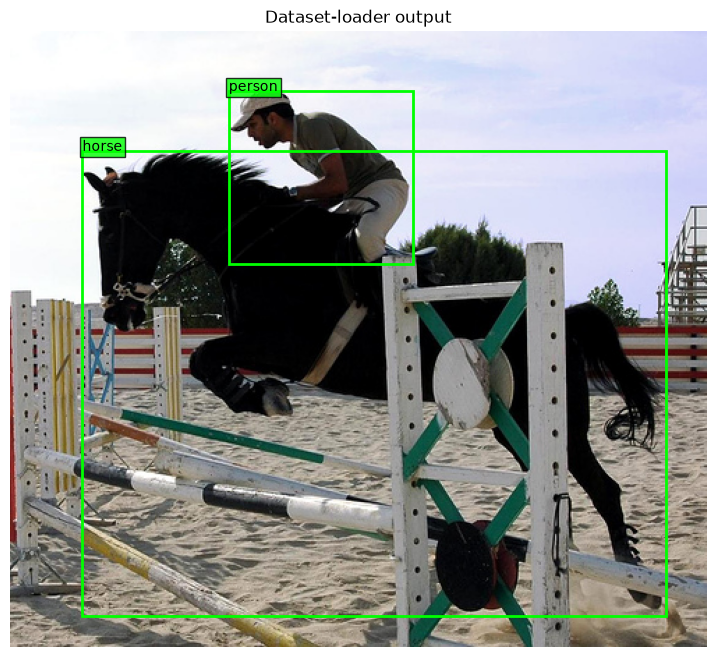

In [35]:
from dataset import VOC_CLASSES
from matplotlib.patches import Rectangle
import matplotlib.pyplot as plt

image, target = training_dataset[0]

display_image = image.permute(1, 2, 0)

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(
    display_image,
    extent=(0, image.shape[2], image.shape[1], 0),
)

for box, label, difficult in zip(
    target["boxes"],
    target["labels"],
    target["difficult"],
):
    xmin, ymin, xmax, ymax = box.tolist()
    category = VOC_CLASSES[label.item() - 1]

    rectangle = Rectangle(
        (xmin, ymin),
        xmax - xmin,
        ymax - ymin,
        fill=False,
        edgecolor="lime",
        linewidth=2,
        linestyle="--" if difficult.item() else "-",
    )
    ax.add_patch(rectangle)

    ax.text(
        xmin,
        ymin,
        category,
        color="black",
        bbox={"facecolor": "lime", "alpha": 0.8, "pad": 2},
    )

ax.set_title("Dataset-loader output")
ax.axis("off")
plt.show()


In [36]:
import importlib
import dataset

importlib.reload(dataset)


<module 'dataset' from '/Users/faikbairamov/Documents/workspace/pascal-voc-object-detection/dataset.py'>

In [37]:
import torch
from torch.utils.data import DataLoader

training_loader = DataLoader(
    training_dataset,
    batch_size=2,
    shuffle=True,
    num_workers=0,
    collate_fn=dataset.detection_collate_fn,
    generator=torch.Generator().manual_seed(42),
)


In [38]:
images, targets = next(iter(training_loader))

print("Images in batch:", len(images))

for index, (image, target) in enumerate(zip(images, targets)):
    print(
        f"Example {index}:",
        "image shape =", tuple(image.shape),
        "boxes shape =", tuple(target["boxes"].shape),
        "labels shape =", tuple(target["labels"].shape),
    )


Images in batch: 2
Example 0: image shape = (3, 500, 375) boxes shape = (3, 4) labels shape = (3,)
Example 1: image shape = (3, 499, 500) boxes shape = (7, 4) labels shape = (7,)


In [39]:
validation_dataset = dataset.VOCDetectionDataset(
    dataset_dir=dataset_dir,
    split_file="splits/dev.txt",
)

validation_loader = DataLoader(
    validation_dataset,
    batch_size=2,
    shuffle=False,
    num_workers=0,
    collate_fn=dataset.detection_collate_fn,
)

print("Validation examples:", len(validation_dataset))

images, targets = next(iter(validation_loader))
print("Images in batch:", len(images))


Validation examples: 1144
Images in batch: 2


In [40]:
import torch

def check_dataset(data):
    for index in range(len(data)):
        image, target = data[index]

        boxes = target["boxes"]
        labels = target["labels"]

        assert image.ndim == 3 and image.shape[0] == 3, index
        assert torch.isfinite(image).all(), index
        assert 0 <= image.min() and image.max() <= 1, index

        assert boxes.ndim == 2 and boxes.shape[1] == 4, index
        assert torch.isfinite(boxes).all(), index
        assert labels.shape == (len(boxes),), index
        assert target["difficult"].shape == labels.shape, index
        assert ((labels >= 1) & (labels <= 20)).all(), index

        height, width = image.shape[1:]

        assert (boxes[:, 0] >= 0).all(), index
        assert (boxes[:, 1] >= 0).all(), index
        assert (boxes[:, 2] <= width).all(), index
        assert (boxes[:, 3] <= height).all(), index
        assert (boxes[:, 2] > boxes[:, 0]).all(), index
        assert (boxes[:, 3] > boxes[:, 1]).all(), index

    print(f"Passed: {len(data)} images")

check_dataset(training_dataset)
check_dataset(validation_dataset)


Passed: 4573 images
Passed: 1144 images


In [41]:
from model import create_model

model = create_model()

print("Output classes:", model.roi_heads.box_predictor.cls_score.out_features)


Output classes: 21


In [42]:
import torch

device = torch.device("cpu")
model = model.to(device)
model.train()

images, targets = next(iter(training_loader))

images = [image.to(device) for image in images]

model_targets = [
    {
        "boxes": target["boxes"].to(device),
        "labels": target["labels"].to(device),
    }
    for target in targets
]

losses = model(images, model_targets)
total_loss = sum(losses.values())

assert torch.isfinite(total_loss), "The loss is not finite."

for name, value in losses.items():
    print(f"{name}: {value.detach().item():.4f}")

print(f"Total loss: {total_loss.detach().item():.4f}")


loss_classifier: 2.8769
loss_box_reg: 0.6970
loss_objectness: 0.0545
loss_rpn_box_reg: 0.0365
Total loss: 3.6648


In [43]:
optimizer = torch.optim.SGD(
    [parameter for parameter in model.parameters() if parameter.requires_grad],
    lr=0.001,
    momentum=0.9,
    weight_decay=0.0005,
)

optimizer.zero_grad()
total_loss.backward()

for name, parameter in model.named_parameters():
    if parameter.grad is not None:
        assert torch.isfinite(parameter.grad).all(), (
            f"Invalid gradient in {name}"
        )

optimizer.step()

print("One training step completed.")


One training step completed.


In [44]:
model.train()
loss_history = []

for step in range(80):
    optimizer.zero_grad()

    losses = model(images, model_targets)
    total_loss = sum(losses.values())

    assert torch.isfinite(total_loss), "Non-finite loss encountered."

    total_loss.backward()
    optimizer.step()

    loss_value = total_loss.detach().item()
    loss_history.append(loss_value)

    if step == 0 or (step + 1) % 5 == 0:
        print(f"Step {step + 1:02d} | Loss: {loss_value:.4f}")


Step 01 | Loss: 3.5986
Step 05 | Loss: 2.6983
Step 10 | Loss: 2.0929
Step 15 | Loss: 1.8428
Step 20 | Loss: 1.6733
Step 25 | Loss: 1.6034
Step 30 | Loss: 1.4144
Step 35 | Loss: 1.3002
Step 40 | Loss: 1.1613
Step 45 | Loss: 1.0500
Step 50 | Loss: 0.9684
Step 55 | Loss: 0.8798
Step 60 | Loss: 0.8210
Step 65 | Loss: 0.7648
Step 70 | Loss: 0.7204
Step 75 | Loss: 0.6964
Step 80 | Loss: 0.6201


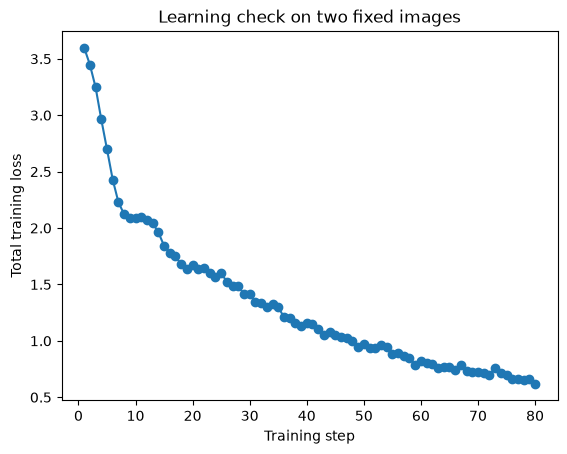

In [45]:
plt.plot(range(1, len(loss_history) + 1), loss_history, marker="o")
plt.xlabel("Training step")
plt.ylabel("Total training loss")
plt.title("Learning check on two fixed images")
plt.show()


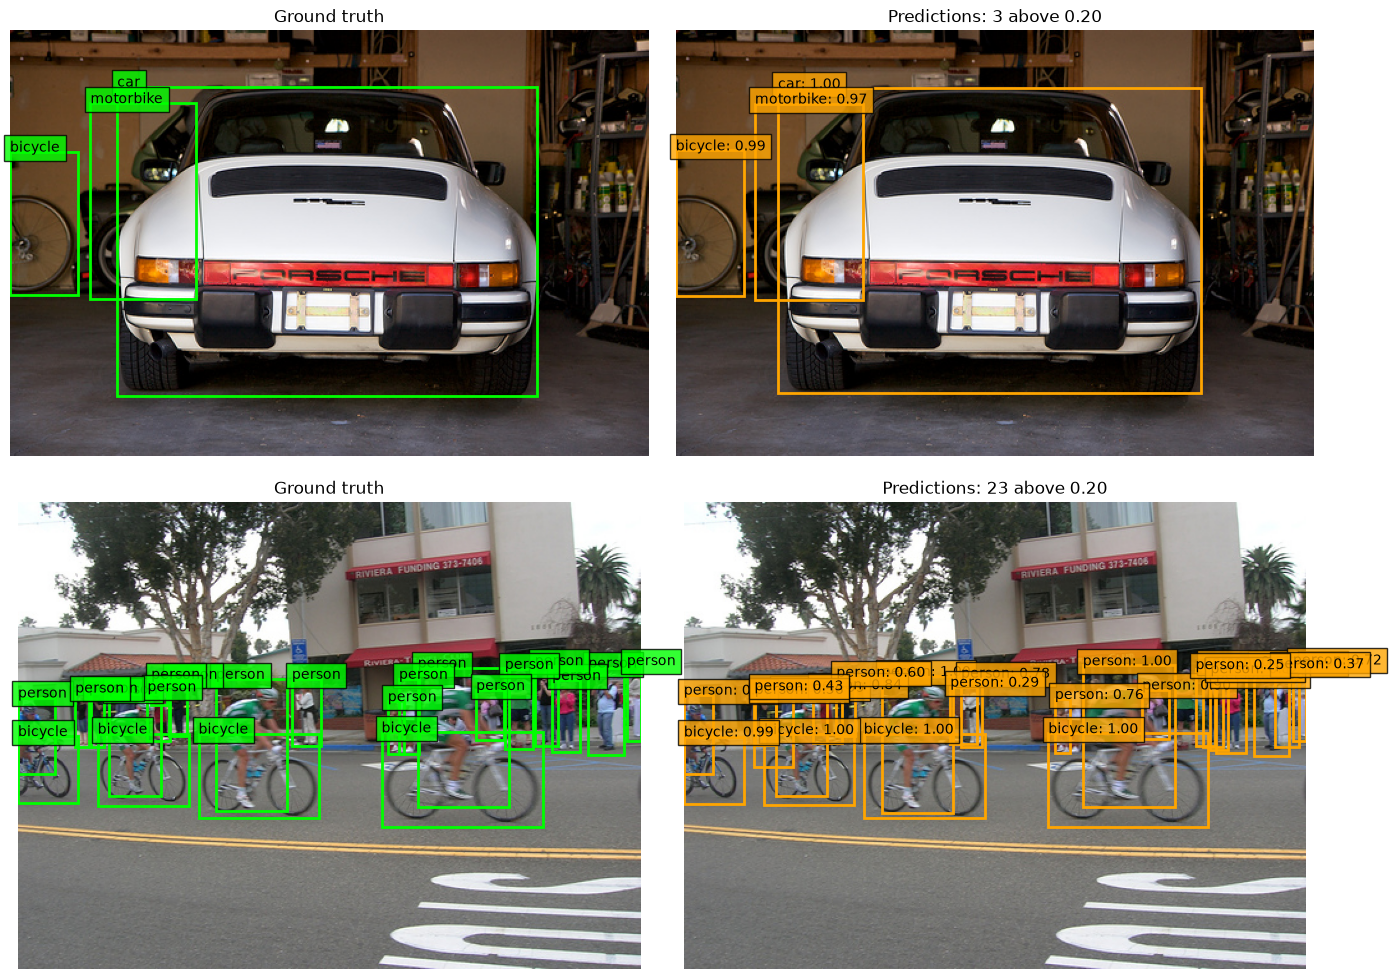

In [46]:
from dataset import VOC_CLASSES
from matplotlib.patches import Rectangle

model.eval()

with torch.no_grad():
    predictions = model(images)

threshold = 0.20

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for row, (image, target, prediction) in enumerate(
    zip(images, model_targets, predictions)
):
    photo = image.detach().cpu().permute(1, 2, 0)
    height, width = photo.shape[:2]

    for ax in axes[row]:
        ax.imshow(photo, extent=(0, width, height, 0))
        ax.axis("off")

    for box, label in zip(target["boxes"], target["labels"]):
        xmin, ymin, xmax, ymax = box.detach().cpu().tolist()
        category = VOC_CLASSES[label.item() - 1]

        axes[row, 0].add_patch(
            Rectangle(
                (xmin, ymin),
                xmax - xmin,
                ymax - ymin,
                fill=False,
                edgecolor="lime",
                linewidth=2,
            )
        )
        axes[row, 0].text(
            xmin, ymin, category,
            bbox={"facecolor": "lime", "alpha": 0.8},
        )

    count = 0

    for box, label, score in zip(
        prediction["boxes"],
        prediction["labels"],
        prediction["scores"],
    ):
        if score.item() < threshold:
            continue

        xmin, ymin, xmax, ymax = box.detach().cpu().tolist()
        category = VOC_CLASSES[label.item() - 1]

        axes[row, 1].add_patch(
            Rectangle(
                (xmin, ymin),
                xmax - xmin,
                ymax - ymin,
                fill=False,
                edgecolor="orange",
                linewidth=2,
            )
        )
        axes[row, 1].text(
            xmin, ymin, f"{category}: {score.item():.2f}",
            bbox={"facecolor": "orange", "alpha": 0.8},
        )
        count += 1

    axes[row, 0].set_title("Ground truth")
    axes[row, 1].set_title(
        f"Predictions: {count} above {threshold:.2f}"
    )

plt.tight_layout()
plt.show()


## 8. Set up local experiment tracking with MLflow

MLflow records experiment settings, metrics, and saved files (artifacts). The earlier two-image check is a sanity check, not a measured baseline.

First, run this in the **project terminal** to install MLflow into this project's environment:

```bash
.venv/bin/python -m pip install mlflow
```

Then run only the two new cells below. They do not depend on earlier training cells, so **do not use Run All**. The first configures local SQLite tracking; the second records a clearly labeled setup check with the split manifests. Neither trains a model nor reports accuracy.

Run these cells with the Pascal VOC `.venv` kernel. If the import fails immediately after installation, restart the kernel and run these two cells again. Record the installed MLflow version as an exact dependency pin after installation succeeds.


In [47]:
from pathlib import Path
import mlflow

project_dir = Path.cwd().resolve()
assert (project_dir / "splits/train.txt").is_file() and (project_dir / "model.py").is_file(), "Set the notebook working directory to pascal-voc-object-detection."
tracking_dir = project_dir / "mlflow_local"
tracking_dir.mkdir(exist_ok=True)
tracking_uri = "sqlite:///" + (tracking_dir / "tracking.db").as_posix()
mlflow.set_tracking_uri(tracking_uri)
experiment_name = "pascal-voc-2012-detection"
experiment = mlflow.get_experiment_by_name(experiment_name)
if experiment is None:
    experiment_id = mlflow.create_experiment(
        name=experiment_name,
        artifact_location=(tracking_dir / "artifacts").as_uri(),
    )
else:
    experiment_id = experiment.experiment_id
mlflow.set_experiment(experiment_id=experiment_id)
print("MLflow version:", mlflow.__version__)
print("Tracking URI:", mlflow.get_tracking_uri())
print(f'MLflow UI command: .venv/bin/mlflow ui --backend-store-uri "{tracking_uri}" --host 127.0.0.1 --port 5000')


2026/10/26 11:07:21 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/10/26 11:07:21 INFO mlflow.store.db.utils: Updating database tables


MLflow version: 3.17.2
Tracking URI: sqlite:////Users/faikbairamov/Documents/workspace/pascal-voc-object-detection/mlflow_local/tracking.db
MLflow UI command: .venv/bin/mlflow ui --backend-store-uri "sqlite:////Users/faikbairamov/Documents/workspace/pascal-voc-object-detection/mlflow_local/tracking.db" --host 127.0.0.1 --port 5000


In [48]:
assert mlflow.active_run() is None, "Finish the active MLflow run before running this setup check."
with mlflow.start_run(run_name="tracking-setup-check") as setup_run:
    mlflow.set_tag("run_type", "setup_check")
    mlflow.set_tag("purpose", "Verify local tracking and split-artifact logging; no training")
    mlflow.log_param("mlflow_version", mlflow.__version__)
    for split_name in ("train", "dev"):
        split_path = project_dir / "splits" / f"{split_name}.txt"
        split_ids = split_path.read_text().splitlines()
        mlflow.log_param(f"{split_name}_images", len(split_ids))
        mlflow.log_artifact(str(split_path), artifact_path="splits")
    print("Setup run ID:", setup_run.info.run_id)
print("Tracking setup check completed; no training was run.")


Setup run ID: dc80742b9a11417da76a765aaa357db0
Tracking setup check completed; no training was run.


## 9. Initialize a clean baseline

Run the cell below once before the first recorded training run. It creates new model weights for the VOC prediction head, a new optimizer, and a newly seeded training loader. The pretrained backbone is loaded again; the earlier two-image updates are not reused.

We keep CPU execution because that is the path already checked with this detector. Apple GPU availability alone does not establish that all detection training operations work there. The seeds make initialization and data ordering repeatable in the same environment; they do not guarantee identical results across machines or library versions.

This cell loads data paths and initializes objects but does **not** train, evaluate, or start an MLflow run. Rerunning it resets baseline progress. Run the MLflow configuration cell first if the kernel has restarted; earlier model-training cells are not required.


In [52]:
import random
import numpy as np
import torch
from torch.utils.data import DataLoader
from dataset import VOCDetectionDataset, detection_collate_fn
from model import create_model

baseline_config = {
    "seed": 42,
    "batch_size": 2,
    "learning_rate": 0.001,
    "momentum": 0.9,
    "weight_decay": 0.0005,
    "device": "cpu",
    "num_classes": 21,
    "difficult_training_policy": "include",
}
random.seed(baseline_config["seed"])
np.random.seed(baseline_config["seed"])
torch.manual_seed(baseline_config["seed"])
baseline_device = torch.device(baseline_config["device"])
baseline_dataset_dir = project_dir.parent / "VOCdevkit" / "VOC2012"
baseline_training_dataset = VOCDetectionDataset(
    dataset_dir=baseline_dataset_dir,
    split_file=project_dir / "splits" / "train.txt",
)
baseline_training_loader = DataLoader(
    baseline_training_dataset,
    batch_size=baseline_config["batch_size"],
    shuffle=True,
    num_workers=0,
    collate_fn=detection_collate_fn,
    generator=torch.Generator().manual_seed(baseline_config["seed"]),
)
baseline_model = create_model(num_classes=baseline_config["num_classes"])
baseline_model = baseline_model.to(baseline_device)
baseline_model.train()
baseline_optimizer = torch.optim.SGD(
    [parameter for parameter in baseline_model.parameters() if parameter.requires_grad],
    lr=baseline_config["learning_rate"],
    momentum=baseline_config["momentum"],
    weight_decay=baseline_config["weight_decay"],
)
assert len(baseline_optimizer.state) == 0, "Expected a fresh optimizer."
assert baseline_model.roi_heads.box_predictor.cls_score.out_features == baseline_config["num_classes"]
print("Baseline device:", baseline_device)
print("Training images:", len(baseline_training_dataset))
print("Output classes:", baseline_config["num_classes"])
print("Optimizer state entries:", len(baseline_optimizer.state))
print("Clean baseline initialized; no training was run.")


Baseline device: cpu
Training images: 4573
Output classes: 21
Optimizer state entries: 0
Clean baseline initialized; no training was run.


In [50]:
import time

with mlflow.start_run(run_name="cpu-training-speed-check"):
    mlflow.set_tag("run_type", "training_speed_check")

    mlflow.log_params(baseline_config)

    mlflow.log_param("planned_batches", 5)

    baseline_model.train()

    started_at = time.perf_counter()

    batch_iterator = iter(baseline_training_loader)

    for step in range(5):
        images, targets = next(batch_iterator)

        images = [image.to(baseline_device) for image in images]

        model_targets = [
            {
                "boxes": target["boxes"].to(baseline_device),
                "labels": target["labels"].to(baseline_device),
            }
            for target in targets
        ]

        baseline_optimizer.zero_grad()

        losses = baseline_model(images, model_targets)

        total_loss = sum(losses.values())

        assert torch.isfinite(total_loss), "Non-finite training loss."

        total_loss.backward()

        baseline_optimizer.step()

        loss_value = total_loss.detach().item()

        mlflow.log_metric("train_total_loss", loss_value, step=step + 1)

        print(f"Batch {step + 1}/5 | Loss: {loss_value:.4f}")

    elapsed_seconds = time.perf_counter() - started_at

    mlflow.log_metric("seconds_per_batch", elapsed_seconds / 5)

    print(f"Average seconds per batch: {elapsed_seconds / 5:.2f}")

Batch 1/5 | Loss: 4.1271
Batch 2/5 | Loss: 4.2159
Batch 3/5 | Loss: 3.7035
Batch 4/5 | Loss: 4.4674
Batch 5/5 | Loss: 3.4313
Average seconds per batch: 0.50


In [51]:
import time


def train_one_epoch(model, loader, optimizer, device, epoch):
    model.train()

    total_weighted_loss = 0.0

    images_seen = 0

    started_at = time.perf_counter()

    for batch_number, (images, targets) in enumerate(loader, start=1):
        images = [image.to(device) for image in images]

        model_targets = [
            {
                "boxes": target["boxes"].to(device),
                "labels": target["labels"].to(device),
            }
            for target in targets
        ]

        optimizer.zero_grad()

        losses = model(images, model_targets)

        loss = sum(losses.values())

        assert torch.isfinite(loss), "Non-finite training loss."

        loss.backward()

        optimizer.step()

        loss_value = loss.detach().item()

        batch_size = len(images)

        total_weighted_loss += loss_value * batch_size

        images_seen += batch_size

        global_step = (epoch - 1) * len(loader) + batch_number

        if batch_number == 1 or batch_number % 100 == 0 or batch_number == len(loader):
            mlflow.log_metric("train_batch_loss", loss_value, step=global_step)

            print(
                f"Epoch {epoch} | Batch {batch_number}/{len(loader)} "
                f"| Loss: {loss_value:.4f}"
            )

    average_loss = total_weighted_loss / images_seen

    elapsed_seconds = time.perf_counter() - started_at

    return {
        "train_loss": average_loss,
        "epoch_seconds": elapsed_seconds,
    }

In [54]:
from pathlib import Path

checkpoint_dir = project_dir / "mlflow_local" / "checkpoints"

checkpoint_dir.mkdir(parents=True, exist_ok=True)

with mlflow.start_run(run_name="mobilenetv3-baseline-1epoch") as run:
    mlflow.set_tag("run_type", "baseline_training")

    mlflow.log_param("architecture", "fasterrcnn_mobilenet_v3_large_320_fpn")

    mlflow.log_params(baseline_config)

    mlflow.log_param("epochs", 1)

    for split_name in ("train", "dev"):
        split_path = project_dir / "splits" / f"{split_name}.txt"

        mlflow.log_artifact(str(split_path), artifact_path="splits")

    results = train_one_epoch(
        model=baseline_model,
        loader=baseline_training_loader,
        optimizer=baseline_optimizer,
        device=baseline_device,
        epoch=1,
    )

    mlflow.log_metrics(results, step=1)

    checkpoint_path = checkpoint_dir / f"{run.info.run_id}_epoch_1.pt"

    torch.save(
        {
            "epoch": 1,
            "model_state_dict": baseline_model.state_dict(),
            "optimizer_state_dict": baseline_optimizer.state_dict(),
            "config": baseline_config,
            "mlflow_run_id": run.info.run_id,
        },
        checkpoint_path,
    )

    mlflow.log_artifact(str(checkpoint_path), artifact_path="checkpoints")

    print(f"Average training loss: {results['train_loss']:.4f}")

    print(f"Epoch duration: {results['epoch_seconds'] / 60:.1f} minutes")

    print("Checkpoint:", checkpoint_path)

Epoch 1 | Batch 1/2287 | Loss: 4.1271
Epoch 1 | Batch 100/2287 | Loss: 1.1789
Epoch 1 | Batch 200/2287 | Loss: 1.9784
Epoch 1 | Batch 300/2287 | Loss: 1.2136
Epoch 1 | Batch 400/2287 | Loss: 1.0636
Epoch 1 | Batch 500/2287 | Loss: 0.5401
Epoch 1 | Batch 600/2287 | Loss: 0.6346
Epoch 1 | Batch 700/2287 | Loss: 0.4319
Epoch 1 | Batch 800/2287 | Loss: 0.3791
Epoch 1 | Batch 900/2287 | Loss: 0.8829
Epoch 1 | Batch 1000/2287 | Loss: 1.8258
Epoch 1 | Batch 1100/2287 | Loss: 0.9073
Epoch 1 | Batch 1200/2287 | Loss: 0.9153
Epoch 1 | Batch 1300/2287 | Loss: 1.2781
Epoch 1 | Batch 1400/2287 | Loss: 2.4414
Epoch 1 | Batch 1500/2287 | Loss: 1.1270
Epoch 1 | Batch 1600/2287 | Loss: 0.4893
Epoch 1 | Batch 1700/2287 | Loss: 1.0721
Epoch 1 | Batch 1800/2287 | Loss: 2.3286
Epoch 1 | Batch 1900/2287 | Loss: 1.0856
Epoch 1 | Batch 2000/2287 | Loss: 1.2939
Epoch 1 | Batch 2100/2287 | Loss: 0.7525
Epoch 1 | Batch 2200/2287 | Loss: 0.9470
Epoch 1 | Batch 2287/2287 | Loss: 0.8898
Average training loss: 1.060

In [65]:
dev_dataset = VOCDetectionDataset(
    dataset_dir=baseline_dataset_dir,
    split_file=project_dir / "splits" / "dev.txt",
)

dev_loader = DataLoader(
    dev_dataset,
    batch_size=2,
    shuffle=False,
    num_workers=0,
    collate_fn=detection_collate_fn,
)

dev_records = []

baseline_model.eval()

with torch.inference_mode():
    for batch_number, (images, targets) in enumerate(dev_loader, start=1):
        images = [image.to(baseline_device) for image in images]

        predictions = baseline_model(images)

        for prediction, target in zip(predictions, targets):
            image_id = dev_dataset.image_ids[len(dev_records)]

            dev_records.append(
                {
                    "image_id": image_id,
                    "prediction": {
                        name: value.detach().cpu()
                        for name, value in prediction.items()
                    },
                    "target": {
                        name: value.detach().cpu()
                        for name, value in target.items()
                    },
                }
            )

        if batch_number % 100 == 0 or batch_number == len(dev_loader):
            print(f"Evaluated {len(dev_records)}/{len(dev_dataset)} images")

assert len(dev_records) == len(dev_dataset)

print("Development predictions collected:", len(dev_records))

Evaluated 200/1144 images
Evaluated 400/1144 images
Evaluated 600/1144 images
Evaluated 800/1144 images
Evaluated 1000/1144 images
Evaluated 1144/1144 images
Development predictions collected: 1144


In [56]:
import numpy as np


def calculate_voc_ap(recall, precision):
    extended_recall = np.concatenate(([0.0], recall, [1.0]))

    extended_precision = np.concatenate(([0.0], precision, [0.0]))

    for index in range(len(extended_precision) - 2, -1, -1):
        extended_precision[index] = max(
            extended_precision[index],
            extended_precision[index + 1],
        )

    change_indices = np.where(
        extended_recall[1:] != extended_recall[:-1]
    )[0]

    ap = np.sum(
        (
            extended_recall[change_indices + 1]
            - extended_recall[change_indices]
        )
        * extended_precision[change_indices + 1]
    )

    return float(ap)

In [57]:
perfect_ap = calculate_voc_ap(
    recall=np.array([0.5, 1.0]),
    precision=np.array([1.0, 1.0]),
)

assert np.isclose(perfect_ap, 1.0)

empty_ap = calculate_voc_ap(
    recall=np.array([]),
    precision=np.array([]),
)

assert np.isclose(empty_ap, 0.0)

print("AP checks passed.")

AP checks passed.


In [58]:
from torchvision.ops import box_iou


def evaluate_category(records, class_id, iou_threshold=0.5):
    ground_truth = {}

    detections = []

    positive_count = 0

    for record in records:
        image_id = record["image_id"]

        target = record["target"]

        mask = target["labels"] == class_id

        boxes = target["boxes"][mask]

        difficult = target["difficult"][mask]

        ground_truth[image_id] = {
            "boxes": boxes,
            "difficult": difficult,
            "matched": np.zeros(len(boxes), dtype=bool),
        }

        positive_count += int((~difficult).sum().item())

        prediction = record["prediction"]

        prediction_mask = prediction["labels"] == class_id

        for score, box in zip(
            prediction["scores"][prediction_mask],
            prediction["boxes"][prediction_mask],
        ):
            detections.append((score.item(), image_id, box))

    assert positive_count > 0, f"No non-difficult objects for class {class_id}."

    detections.sort(key=lambda detection: detection[0], reverse=True)

    true_positives = np.zeros(len(detections))

    false_positives = np.zeros(len(detections))

    for index, (_, image_id, box) in enumerate(detections):
        truth = ground_truth[image_id]

        if len(truth["boxes"]) == 0:
            false_positives[index] = 1

            continue

        overlaps = box_iou(box.unsqueeze(0), truth["boxes"])[0]

        best_index = int(overlaps.argmax().item())

        best_iou = overlaps[best_index].item()

        if best_iou > iou_threshold:
            if truth["difficult"][best_index].item():
                continue

            if not truth["matched"][best_index]:
                true_positives[index] = 1

                truth["matched"][best_index] = True

            else:
                false_positives[index] = 1

        else:
            false_positives[index] = 1

    cumulative_tp = np.cumsum(true_positives)

    cumulative_fp = np.cumsum(false_positives)

    recall = cumulative_tp / positive_count

    precision = cumulative_tp / np.maximum(
        cumulative_tp + cumulative_fp,
        np.finfo(float).eps,
    )

    return {
        "ap": calculate_voc_ap(recall, precision),
        "recall": recall,
        "precision": precision,
        "objects": positive_count,
    }

In [59]:
person_class_id = VOC_CLASSES.index("person") + 1

person_result = evaluate_category(dev_records, person_class_id)

print(f"Person AP@0.5: {person_result['ap']:.2%}")

print("Person ground-truth objects:", person_result["objects"])

Person AP@0.5: 76.03%
Person ground-truth objects: 895


In [67]:
import pandas as pd

category_results = {}

evaluation_rows = []

for class_id, category in enumerate(VOC_CLASSES, start=1):
    result = evaluate_category(dev_records, class_id)

    category_results[category] = result

    evaluation_rows.append(
        {
            "category": category,
            "ap50": result["ap"],
            "objects": result["objects"],
        }
    )

evaluation_df = pd.DataFrame(evaluation_rows).set_index("category")

dev_map50 = evaluation_df["ap50"].mean()

print(f"Development mAP@0.5: {dev_map50:.2%}")

display(
    evaluation_df.sort_values("ap50", ascending=False).style.format(
        {"ap50": "{:.2%}"}
    )
)

Development mAP@0.5: 70.66%


,ap50,objects
category,,
dog,86.29%,147
cat,86.14%,118
aeroplane,83.93%,81
train,83.40%,55
bus,80.44%,63
motorbike,78.93%,63
bicycle,78.87%,56
bird,77.41%,107
person,77.34%,895


In [61]:
baseline_run_id = "d43c960633a7477e8e8d719de3a27338"

assert mlflow.active_run() is None, "Finish the active run first."

with mlflow.start_run(run_id=baseline_run_id):
    mlflow.log_metric("dev_map50", float(dev_map50), step=1)

    mlflow.log_param("dev_images", len(dev_records))

    mlflow.set_tag("evaluation_method", "VOC all-points interpolated AP")

    mlflow.set_tag("evaluation_difficult_policy", "Ignore matches to difficult objects")

    for category, result in category_results.items():
        mlflow.log_metric(
            f"dev_ap50_{category}",
            float(result["ap"]),
            step=1,
        )

    results_csv = evaluation_df.to_csv()

    mlflow.log_text(
        results_csv,
        artifact_file="evaluation/dev_per_category_ap50.csv",
    )

    print(f"Saved development mAP@0.5: {dev_map50:.2%}")

Saved development mAP@0.5: 69.84%


In [62]:
def make_evaluation_test(predicted_boxes, scores, difficult=False):
    return [{
        "image_id": "evaluation_test",
        "target": {
            "boxes": torch.tensor([[0, 0, 10, 10]], dtype=torch.float32),
            "labels": torch.tensor([1], dtype=torch.int64),
            "difficult": torch.tensor([difficult], dtype=torch.bool),
        },
        "prediction": {
            "boxes": torch.tensor(
                predicted_boxes, dtype=torch.float32
            ).reshape(-1, 4),
            "labels": torch.ones(len(scores), dtype=torch.int64),
            "scores": torch.tensor(scores, dtype=torch.float32),
        },
    }]


perfect = evaluate_category(
    make_evaluation_test([[0, 0, 10, 10]], [0.9]),
    class_id=1,
)

assert np.isclose(perfect["ap"], 1.0)

false_first = evaluate_category(
    make_evaluation_test(
        [[20, 20, 30, 30], [0, 0, 10, 10]],
        [0.9, 0.8],
    ),
    class_id=1,
)

assert np.isclose(false_first["ap"], 0.5)

duplicate = evaluate_category(
    make_evaluation_test(
        [[0, 0, 10, 10], [0, 0, 10, 10]],
        [0.9, 0.8],
    ),
    class_id=1,
)

assert np.allclose(duplicate["recall"], [1.0, 1.0])

assert np.allclose(duplicate["precision"], [1.0, 0.5])

difficult_record = make_evaluation_test(
    [[0, 0, 10, 10]],
    [0.99],
    difficult=True,
)

difficult_record[0]["image_id"] = "difficult_test"

mixed_records = difficult_record + make_evaluation_test(
    [[0, 0, 10, 10]],
    [0.9],
)

difficult_result = evaluate_category(mixed_records, class_id=1)

assert difficult_result["objects"] == 1

assert np.isclose(difficult_result["ap"], 1.0)

print("Evaluator matching checks passed.")

Evaluator matching checks passed.


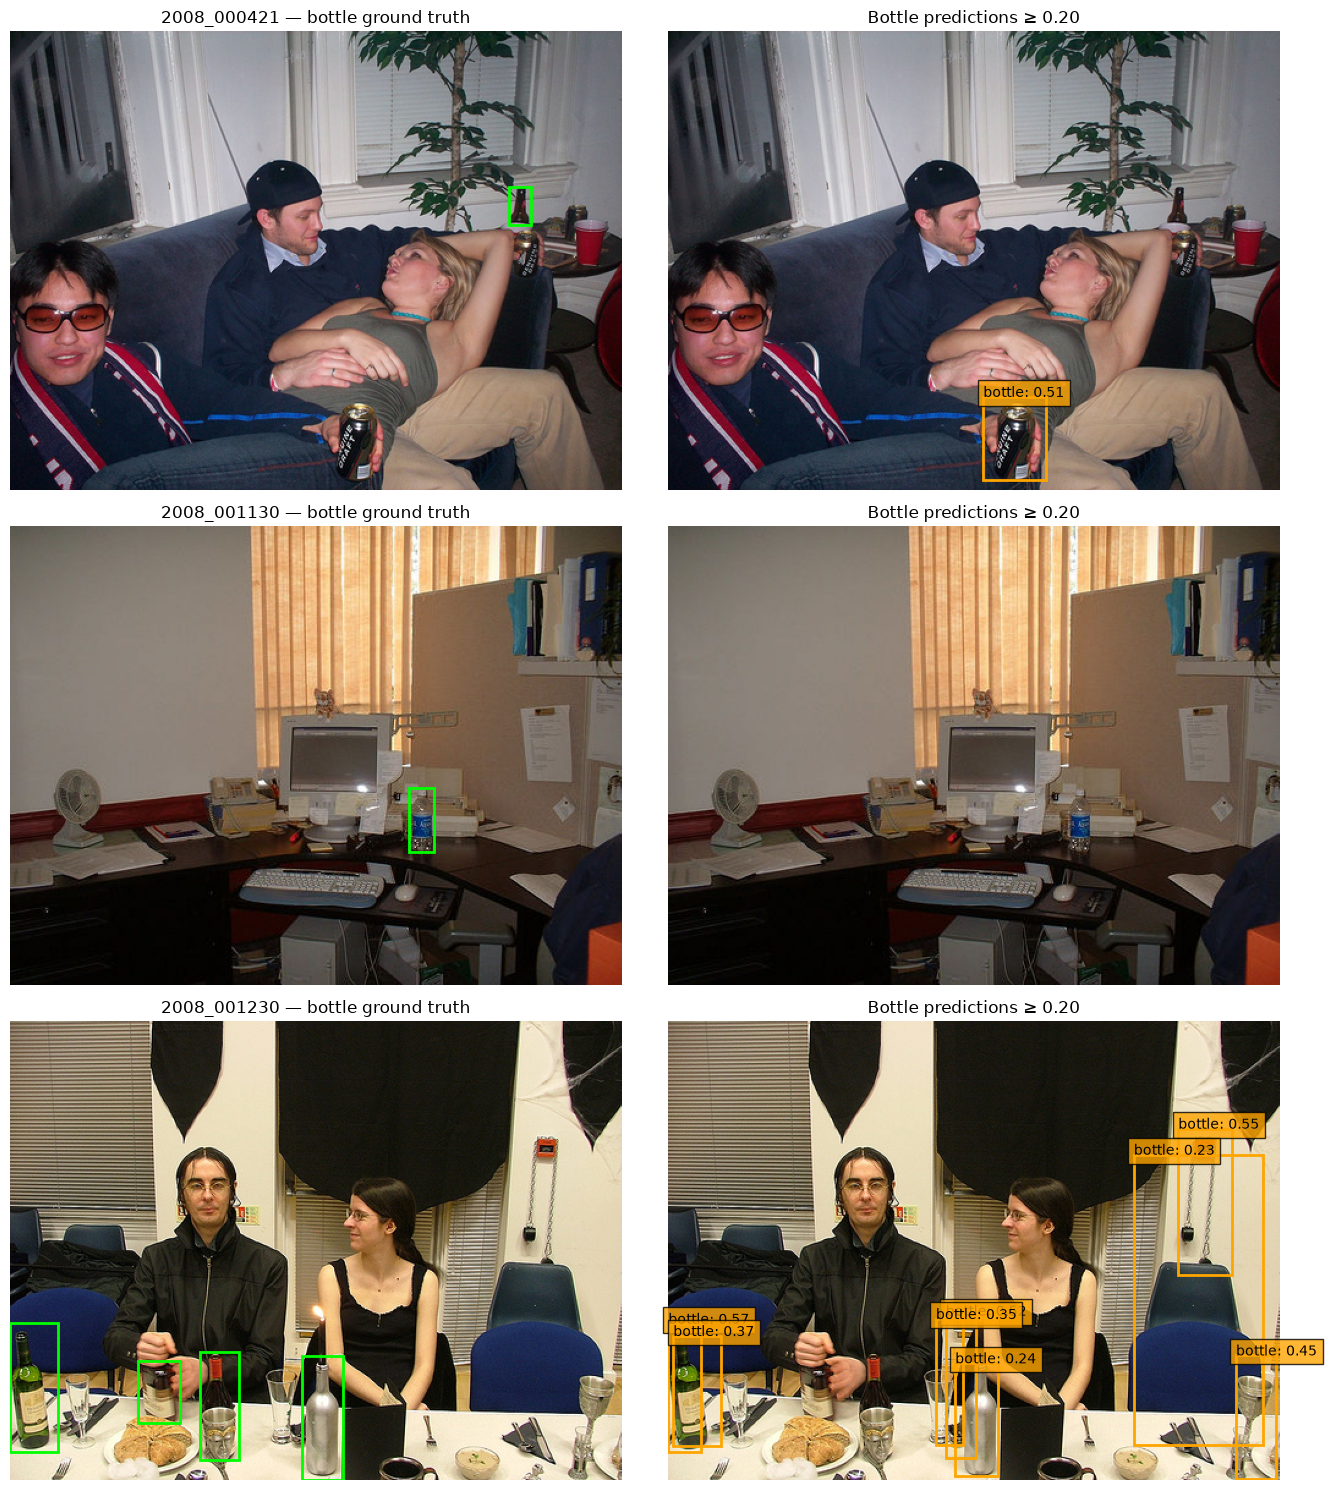

In [63]:
from dataset import VOC_CLASSES

from matplotlib.patches import Rectangle

bottle_id = VOC_CLASSES.index("bottle") + 1

bottle_examples = [
    (index, record)
    for index, record in enumerate(dev_records)
    if (
        (record["target"]["labels"] == bottle_id)
        & ~record["target"]["difficult"]
    ).any().item()
][:3]

fig, axes = plt.subplots(len(bottle_examples), 2, figsize=(14, 5 * len(bottle_examples)))

for row, (index, record) in enumerate(bottle_examples):
    image, _ = dev_dataset[index]

    photo = image.permute(1, 2, 0)

    height, width = photo.shape[:2]

    for ax in axes[row]:
        ax.imshow(photo, extent=(0, width, height, 0))

        ax.axis("off")

    for box, label, difficult in zip(
        record["target"]["boxes"],
        record["target"]["labels"],
        record["target"]["difficult"],
    ):
        if label.item() != bottle_id:
            continue

        xmin, ymin, xmax, ymax = box.tolist()

        axes[row, 0].add_patch(
            Rectangle(
                (xmin, ymin), xmax - xmin, ymax - ymin,
                fill=False, edgecolor="lime", linewidth=2,
                linestyle="--" if difficult.item() else "-",
            )
        )

    prediction = record["prediction"]

    for box, label, score in zip(
        prediction["boxes"],
        prediction["labels"],
        prediction["scores"],
    ):
        if label.item() != bottle_id or score.item() < 0.20:
            continue

        xmin, ymin, xmax, ymax = box.tolist()

        axes[row, 1].add_patch(
            Rectangle(
                (xmin, ymin), xmax - xmin, ymax - ymin,
                fill=False, edgecolor="orange", linewidth=2,
            )
        )

        axes[row, 1].text(
            xmin, ymin, f"bottle: {score.item():.2f}",
            bbox={"facecolor": "orange", "alpha": 0.8},
        )

    axes[row, 0].set_title(f"{record['image_id']} — bottle ground truth")

    axes[row, 1].set_title("Bottle predictions ≥ 0.20")

plt.tight_layout()

plt.show()

In [64]:
with mlflow.start_run(run_id=baseline_run_id):
    mlflow.set_tag("completed_epochs_before_training", 1)

    results_epoch2 = train_one_epoch(
        model=baseline_model,
        loader=baseline_training_loader,
        optimizer=baseline_optimizer,
        device=baseline_device,
        epoch=2,
    )

    mlflow.log_metrics(results_epoch2, step=2)

    checkpoint_path_epoch2 = (
        checkpoint_dir / f"{baseline_run_id}_epoch_2.pt"
    )

    torch.save(
        {
            "epoch": 2,
            "model_state_dict": baseline_model.state_dict(),
            "optimizer_state_dict": baseline_optimizer.state_dict(),
            "config": baseline_config,
            "mlflow_run_id": baseline_run_id,
        },
        checkpoint_path_epoch2,
    )

    mlflow.log_artifact(
        str(checkpoint_path_epoch2),
        artifact_path="checkpoints",
    )

    mlflow.set_tag("completed_epochs", 2)

    mlflow.set_tag("training_plan", "Initially 1 epoch; extended to 2")

    print(f"Epoch 2 average loss: {results_epoch2['train_loss']:.4f}")

    print(f"Epoch duration: {results_epoch2['epoch_seconds'] / 60:.1f} minutes")

    print("Checkpoint:", checkpoint_path_epoch2)

Epoch 2 | Batch 1/2287 | Loss: 0.4091
Epoch 2 | Batch 100/2287 | Loss: 0.7647
Epoch 2 | Batch 200/2287 | Loss: 0.6759
Epoch 2 | Batch 300/2287 | Loss: 0.8500
Epoch 2 | Batch 400/2287 | Loss: 0.5147
Epoch 2 | Batch 500/2287 | Loss: 1.1566
Epoch 2 | Batch 600/2287 | Loss: 1.2749
Epoch 2 | Batch 700/2287 | Loss: 0.9244
Epoch 2 | Batch 800/2287 | Loss: 0.7935
Epoch 2 | Batch 900/2287 | Loss: 0.4662
Epoch 2 | Batch 1000/2287 | Loss: 0.9611
Epoch 2 | Batch 1100/2287 | Loss: 0.8647
Epoch 2 | Batch 1200/2287 | Loss: 0.8309
Epoch 2 | Batch 1300/2287 | Loss: 0.3522
Epoch 2 | Batch 1400/2287 | Loss: 0.7823
Epoch 2 | Batch 1500/2287 | Loss: 0.8919
Epoch 2 | Batch 1600/2287 | Loss: 0.7055
Epoch 2 | Batch 1700/2287 | Loss: 1.5590
Epoch 2 | Batch 1800/2287 | Loss: 0.4449
Epoch 2 | Batch 1900/2287 | Loss: 0.8485
Epoch 2 | Batch 2000/2287 | Loss: 0.8100
Epoch 2 | Batch 2100/2287 | Loss: 0.6447
Epoch 2 | Batch 2200/2287 | Loss: 0.7235
Epoch 2 | Batch 2287/2287 | Loss: 0.8455
Epoch 2 average loss: 0.8142

In [68]:
with mlflow.start_run(run_id=baseline_run_id):
    mlflow.log_metric("dev_map50", float(dev_map50), step=2)

    for category, result in category_results.items():
        mlflow.log_metric(
            f"dev_ap50_{category}",
            float(result["ap"]),
            step=2,
        )

    mlflow.log_text(
        evaluation_df.to_csv(),
        artifact_file="evaluation/dev_per_category_ap50_epoch_2.csv",
    )

    print(f"Saved epoch 2 development mAP@0.5: {dev_map50:.2%}")

Saved epoch 2 development mAP@0.5: 70.66%
